# SAMS Fusion: risk classification training

This notebook trains the three-class fusion model (NORMAL / CAUTION / DANGER) that SAMS uses to combine vision and vibration signals. The live service (`monitoring/services/fusion_inference.py`) loads `models/fusion/best_fusion_model/model.joblib` and reads input columns from `metadata.json` (`feature_cols`).

Until synchronized SAMS experiment logs exist, this notebook builds a **documented rule-guided synthetic dataset** with the same ten base features as production. Replace it later with `datasets/fusion/fusion_experiment_logs.csv`.

## Experiments

| Id | Model |
|----|-------|
| fusion_exp01_random_forest | Random Forest |
| fusion_exp02_xgboost | XGBoost |
| fusion_exp03_svm_rbf | SVM RBF |
| fusion_exp04_mlp | MLP with early stopping |

## Primary metric

**danger_recall** - missed DANGER events are the costliest error.

## Steps

| Section | Step |
|---------|------|
| 0 | Setup, configuration, feature list |
| 1 | Build fusion dataset (synthetic or CSV) |
| 2 | EDA and PCA |
| 3 | Trial holdout split |
| 4 | Utilities and hyperparameter tables |
| 5 | Experiments |
| 6 | Compare, promote best, model card |
| 7 | Limitations |

## 0. Setup

### 0.1 Paths

In [1]:
from pathlib import Path

IN_COLAB = False
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    SAMS_ROOT = Path("/content/SAMS")
else:
    SAMS_ROOT = Path("./SAMS_runtime")

for folder in [
    SAMS_ROOT / "datasets" / "fusion",
    SAMS_ROOT / "models" / "fusion",
    SAMS_ROOT / "results" / "fusion",
]:
    folder.mkdir(parents=True, exist_ok=True)

In [2]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/SAMS")
else:
    here = Path.cwd().resolve()
    if (here / "manage.py").exists():
        DRIVE_ROOT = here
    elif (here.parent / "manage.py").exists():
        DRIVE_ROOT = here.parent
    else:
        DRIVE_ROOT = Path("./SAMS_drive_mirror")

MODELS_DIR = DRIVE_ROOT / "models" / "fusion"
RESULTS_DIR = DRIVE_ROOT / "results" / "fusion"
DATA_DIR = SAMS_ROOT / "datasets" / "fusion"
for folder in [MODELS_DIR, RESULTS_DIR, DATA_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


### 0.2 Packages

In [3]:
import subprocess, sys
PACKAGES = ["pandas", "numpy", "matplotlib", "seaborn", "scikit-learn", "joblib", "tqdm", "xgboost"]
if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *PACKAGES])

In [4]:
import json
import time
import warnings
from datetime import datetime, timezone
from typing import Any, Dict, List, Optional

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from tqdm.auto import tqdm
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

### 0.3 Configuration

In [5]:
SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

CLASS_NAMES = ["NORMAL", "CAUTION", "DANGER"]
LABEL_TO_IDX = {"NORMAL": 0, "CAUTION": 1, "DANGER": 2}
IDX_TO_LABEL = {v: k for k, v in LABEL_TO_IDX.items()}

CAUTION_ZONE_M = 2.0
DANGER_ZONE_M = 0.8
N_TRIALS = 60
SAMPLES_PER_TRIAL = 40
MLP_MAX_ITER = 300
MLP_PATIENCE = 15

config_table = pd.DataFrame([
    {"setting": "SEED", "value": SEED, "meaning": "Random seed"},
    {"setting": "CAUTION_ZONE_M", "value": CAUTION_ZONE_M, "meaning": "Distance threshold for caution zone (m)"},
    {"setting": "DANGER_ZONE_M", "value": DANGER_ZONE_M, "meaning": "Distance threshold for danger zone (m)"},
    {"setting": "N_TRIALS", "value": N_TRIALS, "meaning": "Synthetic experimental trials"},
    {"setting": "SAMPLES_PER_TRIAL", "value": SAMPLES_PER_TRIAL, "meaning": "Fusion rows per trial"},
    {"setting": "MLP_MAX_ITER", "value": MLP_MAX_ITER, "meaning": "Max MLP epochs (sklearn early stopping)"},
    {"setting": "MLP_PATIENCE", "value": MLP_PATIENCE, "meaning": "MLP validation patience"},
]).set_index("setting")
config_table.to_csv(RESULTS_DIR / "config.csv")
display(config_table)

,value,meaning
setting,,
SEED,42.0,Random seed
CAUTION_ZONE_M,2.0,Distance threshold for caution zone (m)
DANGER_ZONE_M,0.8,Distance threshold for danger zone (m)
N_TRIALS,60.0,Synthetic experimental trials
SAMPLES_PER_TRIAL,40.0,Fusion rows per trial
MLP_MAX_ITER,300.0,Max MLP epochs (sklearn early stopping)
MLP_PATIENCE,15.0,MLP validation patience


### 0.4 Feature columns (live contract)

In [6]:
BASE_FEATURE_COLS = [
    "worker_detected",
    "worker_distance",
    "inside_caution_zone",
    "inside_danger_zone",
    "worker_speed",
    "approaching_machine",
    "vision_confidence",
    "machine_active",
    "vibration_state",
    "vibration_anomaly_score",
]
FEATURE_COLS = list(BASE_FEATURE_COLS)
display(pd.DataFrame({'feature': FEATURE_COLS}))

,feature
0,worker_detected
1,worker_distance
2,inside_caution_zone
3,inside_danger_zone
4,worker_speed
5,approaching_machine
6,vision_confidence
7,machine_active
8,vibration_state
9,vibration_anomaly_score


### 0.5 Helpers

In [7]:
def save_table(frame: pd.DataFrame, name: str) -> None:
    path = RESULTS_DIR / f"{name}.csv"
    frame.to_csv(path)
    display(frame)


def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> Dict[str, Any]:
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    normal_mask = y_true == 0
    false_alarm_rate = float(((y_pred[normal_mask] != 0).sum() / max(1, normal_mask.sum())))
    per_p = precision_score(y_true, y_pred, labels=[0, 1, 2], average=None, zero_division=0)
    per_r = recall_score(y_true, y_pred, labels=[0, 1, 2], average=None, zero_division=0)
    per_f = f1_score(y_true, y_pred, labels=[0, 1, 2], average=None, zero_division=0)
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_macro": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "danger_precision": float(per_p[2]),
        "danger_recall": float(per_r[2]),
        "danger_f1": float(per_f[2]),
        "missed_dangers": int(((y_true == 2) & (y_pred != 2)).sum()),
        "false_alarm_rate": false_alarm_rate,
        "confusion_matrix": cm.tolist(),
        "classification_report": classification_report(
            y_true, y_pred, labels=[0, 1, 2], target_names=CLASS_NAMES, digits=4, zero_division=0
        ),
    }


HYPERPARAMS: Dict[str, pd.DataFrame] = {}


def register_hyperparams(exp_id: str, rows: List[Dict[str, Any]]) -> None:
    frame = pd.DataFrame(rows)
    HYPERPARAMS[exp_id] = frame
    save_table(frame.set_index("parameter"), f"hyperparams_{exp_id}")

## 1. Build fusion dataset

If `fusion_experiment_logs.csv` exists on disk, it is used. Otherwise we generate rule-guided synthetic trials.

In [8]:
SCENARIOS = [
    "machine_idle",
    "worker_approach",
    "worker_in_caution",
    "worker_in_danger",
    "high_vibration",
    "ppe_missing_far",
]


def assign_risk_label(row: pd.Series) -> int:
    if row["inside_danger_zone"] >= 0.5 or row["worker_distance"] <= DANGER_ZONE_M:
        return 2
    if row["inside_caution_zone"] >= 0.5 or row["worker_distance"] <= CAUTION_ZONE_M:
        return 1
    if row["vibration_state"] >= 0.5 and row["worker_distance"] <= CAUTION_ZONE_M * 1.5:
        return 1
    return 0


def generate_trial_samples(trial_id: int, scenario: str, n: int, local_rng: np.random.Generator) -> pd.DataFrame:
    rows = []
    dist = local_rng.uniform(0.4, 4.0)
    for t in range(n):
        dist = float(np.clip(dist + local_rng.normal(0, 0.08), 0.3, 5.0))
        worker_detected = 1.0 if scenario != "machine_idle" else float(local_rng.random() > 0.3)
        machine_active = 1.0 if scenario != "machine_idle" else float(local_rng.random() > 0.6)
        vib = float(local_rng.random() * (1.2 if scenario == "high_vibration" else 0.4))
        row = {
            "trial_id": trial_id,
            "scenario": scenario,
            "t": t,
            "worker_detected": worker_detected,
            "worker_distance": dist,
            "inside_caution_zone": float(dist <= CAUTION_ZONE_M),
            "inside_danger_zone": float(dist <= DANGER_ZONE_M),
            "worker_speed": float(local_rng.uniform(0, 1.5)),
            "approaching_machine": float(local_rng.random() > 0.55),
            "vision_confidence": float(local_rng.uniform(0.5, 0.99)),
            "machine_active": machine_active,
            "vibration_state": float(vib > 0.55),
            "vibration_anomaly_score": vib,
        }
        rows.append(row)
    trial_df = pd.DataFrame(rows)
    trial_df["label"] = trial_df.apply(assign_risk_label, axis=1)
    trial_df["label_name"] = trial_df["label"].map(IDX_TO_LABEL)
    return trial_df


def build_fusion_dataset(n_trials: int, samples_per_trial: int, seed: int) -> pd.DataFrame:
    local_rng = np.random.default_rng(seed)
    scenario_cycle = (SCENARIOS * ((n_trials // len(SCENARIOS)) + 1))[:n_trials]
    frames = []
    for tid, sc in enumerate(tqdm(scenario_cycle, desc="Generating trials")):
        frames.append(generate_trial_samples(tid, sc, samples_per_trial, local_rng))
    return pd.concat(frames, ignore_index=True)


real_log = DATA_DIR / "fusion_experiment_logs.csv"
if real_log.exists():
    fusion_df = pd.read_csv(real_log)
    DATA_SOURCE = "real_logs"
else:
    print("No real logs - generating rule-guided synthetic fusion dataset.")
    fusion_df = build_fusion_dataset(N_TRIALS, SAMPLES_PER_TRIAL, SEED)
    DATA_SOURCE = "synthetic_rule_guided"

out_csv = DATA_DIR / "fusion_dataset.csv"
fusion_df.to_csv(out_csv, index=False)
print("Rows:", len(fusion_df), "Trials:", fusion_df["trial_id"].nunique(), "Source:", DATA_SOURCE)
display(fusion_df.head())

No real logs - generating rule-guided synthetic fusion dataset.


Generating trials:   0%|          | 0/60 [00:00<?, ?it/s]

Rows: 2400 Trials: 60 Source: synthetic_rule_guided


,trial_id,scenario,t,worker_detected,worker_distance,inside_caution_zone,inside_danger_zone,worker_speed,approaching_machine,vision_confidence,machine_active,vibration_state,vibration_anomaly_score,label,label_name
0,0,machine_idle,0,1.0,3.103043,0.0,0.0,1.463434,1.0,0.885172,1.0,0.0,0.037671,0,NORMAL
1,0,machine_idle,1,1.0,3.101699,0.0,0.0,0.965798,1.0,0.717273,0.0,0.0,0.370706,0,NORMAL
2,0,machine_idle,2,1.0,3.032956,0.0,0.0,0.947497,1.0,0.673718,0.0,0.0,0.331052,0,NORMAL
3,0,machine_idle,3,1.0,3.130759,0.0,0.0,0.700082,0.0,0.575602,1.0,0.0,0.077855,0,NORMAL
4,0,machine_idle,4,1.0,3.165225,0.0,0.0,0.555690,0.0,0.592841,1.0,0.0,0.130330,0,NORMAL


## 1.1 Dataset preview

The fusion set is tabular, not images. The table below shows three random rows from each risk class. The scatter plot is worker distance against vibration anomaly score, which is the pair the risk rules use most directly. Check that DANGER rows sit close to the machine and that NORMAL rows sit farther out.

,trial_id,scenario,label_name,worker_detected,worker_distance,inside_caution_zone,inside_danger_zone,worker_speed,approaching_machine,vision_confidence,machine_active,vibration_state,vibration_anomaly_score
0,55,worker_approach,NORMAL,1.0,3.667008,0.0,0.0,1.363059,0.0,0.749482,1.0,0.0,0.143288
1,44,worker_in_caution,NORMAL,1.0,2.288537,0.0,0.0,0.955965,0.0,0.737517,1.0,0.0,0.365300
2,54,machine_idle,NORMAL,1.0,2.583102,0.0,0.0,0.685637,0.0,0.636468,0.0,0.0,0.169313
3,17,ppe_missing_far,CAUTION,1.0,1.310871,1.0,0.0,1.131542,1.0,0.907860,1.0,0.0,0.396899
4,47,ppe_missing_far,CAUTION,1.0,1.304607,1.0,0.0,0.625567,1.0,0.733289,1.0,0.0,0.022457
5,16,high_vibration,CAUTION,1.0,2.483038,0.0,0.0,0.934037,0.0,0.848424,1.0,1.0,1.111011
6,53,ppe_missing_far,DANGER,1.0,0.561834,1.0,1.0,1.490002,0.0,0.941958,1.0,0.0,0.333007
7,6,machine_idle,DANGER,1.0,0.702125,1.0,1.0,0.844009,1.0,0.626137,0.0,0.0,0.085816
8,23,ppe_missing_far,DANGER,1.0,0.462561,1.0,1.0,0.823905,0.0,0.795294,1.0,0.0,0.109874


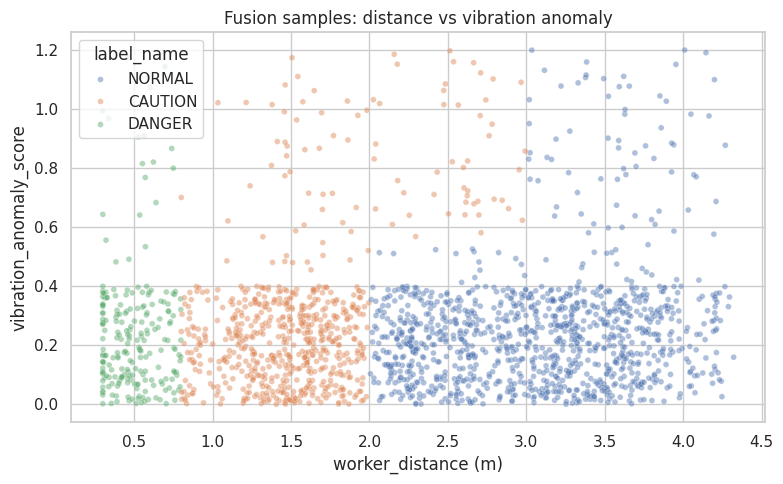

In [9]:
preview_parts = []
for class_name in CLASS_NAMES:
    subset = fusion_df[fusion_df["label_name"] == class_name]
    preview_parts.append(subset.sample(n=min(3, len(subset)), random_state=SEED))
preview = pd.concat(preview_parts)
show_cols = ["trial_id", "scenario", "label_name"] + FEATURE_COLS
save_table(preview[show_cols].reset_index(drop=True), "fusion_dataset_preview")

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
    data=fusion_df.sample(n=min(2000, len(fusion_df)), random_state=SEED),
    x="worker_distance",
    y="vibration_anomaly_score",
    hue="label_name",
    hue_order=CLASS_NAMES,
    alpha=0.45,
    s=18,
    ax=ax,
)
ax.set_title("Fusion samples: distance vs vibration anomaly")
ax.set_xlabel("worker_distance (m)")
ax.set_ylabel("vibration_anomaly_score")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fusion_dataset_preview.png", dpi=140, bbox_inches="tight")
plt.show()

## 2. EDA and PCA

,count
label_name,
NORMAL,1332
CAUTION,814
DANGER,254


,count,mean,std,min,25%,50%,75%,max
worker_detected,2400.0,0.949167,0.219703,0.000000,1.000000,1.000000,1.000000,1.000000
worker_distance,2400.0,2.280969,1.060173,0.300000,1.461778,2.292779,3.205231,4.338655
inside_caution_zone,2400.0,0.420417,0.493729,0.000000,0.000000,0.000000,1.000000,1.000000
inside_danger_zone,2400.0,0.105833,0.307688,0.000000,0.000000,0.000000,0.000000,1.000000
worker_speed,2400.0,0.744315,0.438561,0.000187,0.353713,0.740472,1.129865,1.499648
approaching_machine,2400.0,0.445833,0.497161,0.000000,0.000000,0.000000,1.000000,1.000000
vision_confidence,2400.0,0.743139,0.138741,0.500454,0.626131,0.743513,0.859044,0.989974
machine_active,2400.0,0.904167,0.294424,0.000000,1.000000,1.000000,1.000000,1.000000
vibration_state,2400.0,0.083333,0.276443,0.000000,0.000000,0.000000,0.000000,1.000000
vibration_anomaly_score,2400.0,0.261010,0.223413,0.000005,0.109297,0.225809,0.332684,1.199972


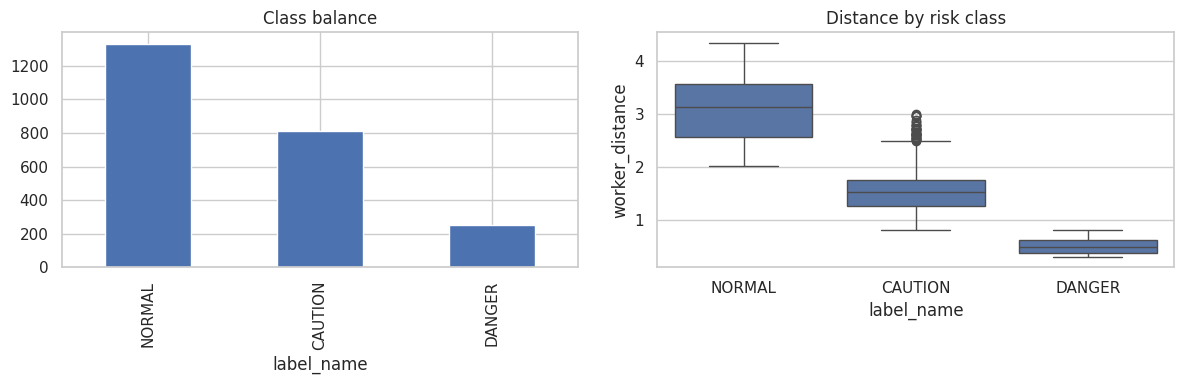

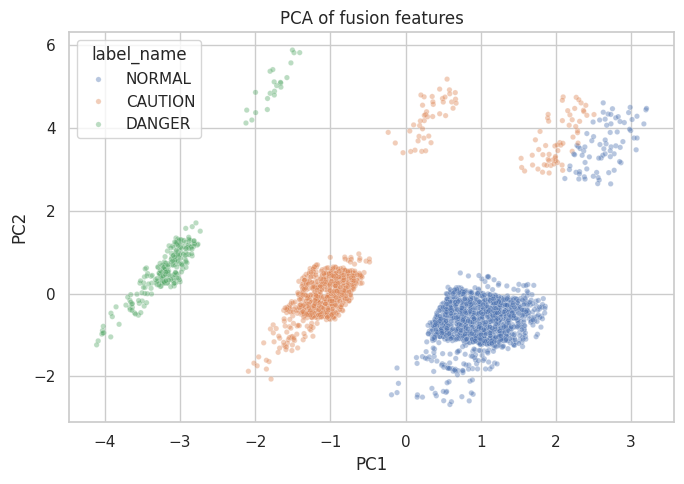

In [10]:
save_table(fusion_df["label_name"].value_counts().reindex(CLASS_NAMES).to_frame("count"), "eda_class_counts")
save_table(fusion_df[FEATURE_COLS].describe().T, "eda_feature_summary")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fusion_df["label_name"].value_counts().reindex(CLASS_NAMES).plot(kind="bar", ax=axes[0])
axes[0].set_title("Class balance")
sns.boxplot(data=fusion_df, x="label_name", y="worker_distance", order=CLASS_NAMES, ax=axes[1])
axes[1].set_title("Distance by risk class")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "eda_fusion.png", dpi=140)
plt.show()

scaler = StandardScaler()
X_pca = scaler.fit_transform(fusion_df[FEATURE_COLS])
coords = PCA(n_components=2, random_state=SEED).fit_transform(X_pca)
pca_df = pd.DataFrame({"PC1": coords[:, 0], "PC2": coords[:, 1], "label_name": fusion_df["label_name"]})
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="label_name", hue_order=CLASS_NAMES, alpha=0.4, s=15, ax=ax)
ax.set_title("PCA of fusion features")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "pca_fusion_features.png", dpi=140)
plt.show()

## 3. Trial holdout split

In [11]:
trial_meta = fusion_df.groupby("trial_id", as_index=False).agg(
    scenario=("scenario", "first"),
    danger_rate=("label", lambda s: float((s == 2).mean())),
)
train_trials, val_trials, test_trials = set(), set(), set()
for scenario, grp in trial_meta.groupby("scenario"):
    ids = grp["trial_id"].to_numpy()
    rng.shuffle(ids)
    n = len(ids)
    n_test = max(1, int(round(0.15 * n)))
    n_val = max(1, int(round(0.15 * n)))
    test_ids = set(ids[:n_test])
    val_ids = set(ids[n_test : n_test + n_val])
    train_ids = set(ids[n_test + n_val :])
    test_trials |= test_ids
    val_trials |= val_ids
    train_trials |= train_ids

save_table(pd.DataFrame([
    {"split": "train", "n_trials": len(train_trials)},
    {"split": "val", "n_trials": len(val_trials)},
    {"split": "test", "n_trials": len(test_trials)},
]), "split_trials")


def mask(trials: set) -> np.ndarray:
    return fusion_df["trial_id"].isin(trials).to_numpy()


train_m, val_m, test_m = mask(train_trials), mask(val_trials), mask(test_trials)
X_train = fusion_df.loc[train_m, FEATURE_COLS].to_numpy(dtype=np.float32)
y_train = fusion_df.loc[train_m, "label"].to_numpy(dtype=np.int64)
X_val = fusion_df.loc[val_m, FEATURE_COLS].to_numpy(dtype=np.float32)
y_val = fusion_df.loc[val_m, "label"].to_numpy(dtype=np.int64)
X_test = fusion_df.loc[test_m, FEATURE_COLS].to_numpy(dtype=np.float32)
y_test = fusion_df.loc[test_m, "label"].to_numpy(dtype=np.int64)

,split,n_trials
0,train,36
1,val,12
2,test,12


## 4. Save experiment helper

In [14]:
def to_json_safe(value):
    """Turn NumPy and pandas values into plain Python types that json can write."""
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, np.bool_):
        return bool(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(f"Object of type {type(value).__name__} is not JSON serializable")


def save_experiment(exp_id: str, approach: str, model_obj, metrics: Dict[str, Any], val_danger_recall: float) -> Path:
    out_dir = MODELS_DIR / exp_id
    out_dir.mkdir(parents=True, exist_ok=True)
    joblib.dump(model_obj, out_dir / "model.joblib")
    meta = {
        "experiment_id": exp_id,
        "approach": approach,
        "task": "fusion_risk_classification",
        "dataset": DATA_SOURCE,
        "class_names": CLASS_NAMES,
        "label_to_idx": LABEL_TO_IDX,
        "feature_cols": FEATURE_COLS,
        "zones_m": {"caution": CAUTION_ZONE_M, "danger": DANGER_ZONE_M},
        "split": {
            "strategy": "trial_holdout",
            "train_trials": sorted(train_trials),
            "val_trials": sorted(val_trials),
            "test_trials": sorted(test_trials),
        },
        "val_danger_recall": float(val_danger_recall),
        "test_metrics": {k: v for k, v in metrics.items() if k != "classification_report"},
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    }
    with open(out_dir / "metadata.json", "w") as f:
        json.dump(meta, f, indent=2, default=to_json_safe)
    cm = pd.DataFrame(metrics["confusion_matrix"], index=CLASS_NAMES, columns=CLASS_NAMES)
    save_table(cm, f"confusion_{exp_id}")
    row = {
        "experiment_id": exp_id,
        "approach": approach,
        "val_danger_recall": val_danger_recall,
        "danger_recall": metrics["danger_recall"],
        "f1_macro": metrics["f1_macro"],
        "accuracy": metrics["accuracy"],
        "missed_dangers": metrics["missed_dangers"],
    }
    ledger_path = RESULTS_DIR / "fusion_experiment_ledger.csv"
    ledger = pd.DataFrame([row])
    if ledger_path.exists():
        prev = pd.read_csv(ledger_path)
        prev = prev[prev["experiment_id"] != exp_id]
        ledger = pd.concat([prev, ledger], ignore_index=True)
    ledger.to_csv(ledger_path, index=False)
    return out_dir

## 5. Experiments

In [15]:
# fusion_exp01 - Random Forest
exp_id = "fusion_exp01_random_forest"
register_hyperparams(exp_id, [
    {"parameter": "n_estimators", "value": 400, "meaning": "Trees"},
    {"parameter": "class_weight", "value": "balanced", "meaning": "Class balance"},
])
rf = RandomForestClassifier(n_estimators=400, class_weight="balanced", random_state=SEED, n_jobs=-1)
rf.fit(X_train, y_train)
val_m = compute_metrics(y_val, rf.predict(X_val))
test_m = compute_metrics(y_test, rf.predict(X_test))
save_experiment(exp_id, "Classical baseline - Random Forest on fusion features", rf, test_m, val_m["danger_recall"])

,value,meaning
parameter,,
n_estimators,400,Trees
class_weight,balanced,Class balance


,NORMAL,CAUTION,DANGER
NORMAL,360,0,0
CAUTION,0,106,0
DANGER,0,0,14


PosixPath('/content/drive/MyDrive/SAMS/models/fusion/fusion_exp01_random_forest')

In [16]:
exp_id = "fusion_exp02_xgboost"
register_hyperparams(exp_id, [
    {"parameter": "n_estimators", "value": 250, "meaning": "Rounds"},
    {"parameter": "max_depth", "value": 5, "meaning": "Depth"},
    {"parameter": "learning_rate", "value": 0.1, "meaning": "Shrinkage"},
])
xgb = XGBClassifier(
    objective="multi:softmax",
    num_class=3,
    n_estimators=250,
    max_depth=5,
    learning_rate=0.1,
    random_state=SEED,
    n_jobs=-1,
)
xgb.fit(X_train, y_train)
val_m = compute_metrics(y_val, xgb.predict(X_val))
test_m = compute_metrics(y_test, xgb.predict(X_test))
save_experiment(exp_id, "Boosted trees - XGBoost on fusion features", xgb, test_m, val_m["danger_recall"])

,value,meaning
parameter,,
n_estimators,250.0,Rounds
max_depth,5.0,Depth
learning_rate,0.1,Shrinkage


,NORMAL,CAUTION,DANGER
NORMAL,360,0,0
CAUTION,0,106,0
DANGER,0,0,14


PosixPath('/content/drive/MyDrive/SAMS/models/fusion/fusion_exp02_xgboost')

In [17]:
exp_id = "fusion_exp03_svm_rbf"
register_hyperparams(exp_id, [
    {"parameter": "C", "value": 5.0, "meaning": "Regularisation"},
    {"parameter": "kernel", "value": "rbf", "meaning": "Kernel"},
    {"parameter": "class_weight", "value": "balanced", "meaning": "Class balance"},
])
svm = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SVC(C=5.0, kernel="rbf", class_weight="balanced", random_state=SEED)),
])
svm.fit(X_train, y_train)
val_m = compute_metrics(y_val, svm.predict(X_val))
test_m = compute_metrics(y_test, svm.predict(X_test))
save_experiment(exp_id, "Margin classifier - SVM RBF on scaled fusion features", svm, test_m, val_m["danger_recall"])

,value,meaning
parameter,,
C,5.0,Regularisation
kernel,rbf,Kernel
class_weight,balanced,Class balance


,NORMAL,CAUTION,DANGER
NORMAL,360,0,0
CAUTION,0,106,0
DANGER,0,0,14


PosixPath('/content/drive/MyDrive/SAMS/models/fusion/fusion_exp03_svm_rbf')

In [18]:
exp_id = "fusion_exp04_mlp"
register_hyperparams(exp_id, [
    {"parameter": "hidden_layer_sizes", "value": "(64, 32)", "meaning": "Layer widths"},
    {"parameter": "early_stopping", "value": True, "meaning": "Stop on val score plateau"},
    {"parameter": "validation_fraction", "value": 0.15, "meaning": "Internal val fraction"},
    {"parameter": "n_iter_no_change", "value": MLP_PATIENCE, "meaning": "Patience epochs"},
    {"parameter": "max_iter", "value": MLP_MAX_ITER, "meaning": "Epoch cap"},
])
mlp = Pipeline([
    ("scaler", StandardScaler()),
    (
        "clf",
        MLPClassifier(
            hidden_layer_sizes=(64, 32),
            max_iter=MLP_MAX_ITER,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=MLP_PATIENCE,
            random_state=SEED,
        ),
    ),
])
mlp.fit(X_train, y_train)
val_m = compute_metrics(y_val, mlp.predict(X_val))
test_m = compute_metrics(y_test, mlp.predict(X_test))
save_experiment(exp_id, "Neural net - MLP on scaled fusion features", mlp, test_m, val_m["danger_recall"])

,value,meaning
parameter,,
hidden_layer_sizes,"(64, 32)",Layer widths
early_stopping,True,Stop on val score plateau
validation_fraction,0.15,Internal val fraction
n_iter_no_change,15,Patience epochs
max_iter,300,Epoch cap


,NORMAL,CAUTION,DANGER
NORMAL,360,0,0
CAUTION,0,106,0
DANGER,0,0,14


PosixPath('/content/drive/MyDrive/SAMS/models/fusion/fusion_exp04_mlp')

## 6. Compare and promote

In [19]:
comparison = pd.read_csv(RESULTS_DIR / "fusion_experiment_ledger.csv")
comparison = comparison.sort_values(["val_danger_recall", "danger_recall"], ascending=False)
save_table(comparison, "experiment_comparison")
winner_id = comparison.iloc[0]["experiment_id"]
print("Best by val_danger_recall:", winner_id)

import shutil

best_dst = MODELS_DIR / "best_fusion_model"
best_dst.mkdir(parents=True, exist_ok=True)
src = MODELS_DIR / winner_id
shutil.copy2(src / "model.joblib", best_dst / "model.joblib")
with open(src / "metadata.json") as f:
    meta = json.load(f)
meta["promoted_from"] = winner_id
meta["selection_metric"] = "val_danger_recall"
with open(best_dst / "metadata.json", "w") as f:
    json.dump(meta, f, indent=2)
print("Promoted to", best_dst)

,experiment_id,approach,val_danger_recall,danger_recall,f1_macro,accuracy,missed_dangers
0,fusion_exp01_random_forest,Classical baseline - Random Forest on fusion f...,1.00,1.0,1.0,1.0,0
1,fusion_exp02_xgboost,Boosted trees - XGBoost on fusion features,1.00,1.0,1.0,1.0,0
2,fusion_exp03_svm_rbf,Margin classifier - SVM RBF on scaled fusion f...,1.00,1.0,1.0,1.0,0
3,fusion_exp04_mlp,Neural net - MLP on scaled fusion features,0.92,1.0,1.0,1.0,0


Best by val_danger_recall: fusion_exp01_random_forest
Promoted to /content/drive/MyDrive/SAMS/models/fusion/best_fusion_model


**Limitations**

1. Synthetic data follows hand-written rules; it is useful for plumbing and feature contracts, not for calibrated on-site risk rates.
2. Trial holdout reduces leakage but scenarios are still simulated.
3. Only the ten base features are used; hazard and approach velocity columns in `fusion_inference.py` are not trained here.
4. Class weights and thresholds in the live app (`decision` block) are not tuned jointly with this sklearn export.
5. Real logs should replace synthesis before trusting DANGER recall numbers for safety sign-off.